# Strojenie SLIC

Porównujemy wybrane warianty na tej samej próbce treningowej w oryginalnej rozdzielczości. Dla wariantu z Sobelem sprawdzamy też wpływ wagi mapy krawędzi.

In [20]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from itertools import product

from skimage.color import rgb2lab
from skimage.filters import sobel
from skimage.segmentation import mark_boundaries, slic
from tqdm import tqdm

from src.dataloader import get_labels
from src.dataloader_slic import get_train_test_val

data = get_train_test_val(include_original_masks=False)
class_names = get_labels()
n_classes = len(class_names)

## 1. Ustawienia eksperymentu

Rozmiar próbki i siatkę parametrów można zmienić w tej komórce. Próbka służy do strojenia. Walidacja i test są dostępne do późniejszej oceny.

In [21]:
SEED = 42
N_TRAIN_IMAGES = 10 # 20
N_SEGMENTS = [6000] # 2500, 3250, 
COMPACTNESS = [0.175] # , 0.2, 0.225
VARIANTS = ['Lab + bilateral + Sobel'] # 'RGB', 'Lab', 'Lab + bilateral', 

SIGMA_COLOR = 10
SIGMA_SPACE = 3
SOBEL_VARIANT = 'Lab + bilateral + Sobel'
SOBEL_WEIGHT = [1] # 0.1, 0.5, 2
MINORITY_THRESHOLD = 0.05

train = data['train']
rng = np.random.default_rng(SEED)
train_indices = rng.choice(len(train['images']), size=N_TRAIN_IMAGES, replace=False)
variant_weights = [
    (variant, weight)
    for variant in VARIANTS
    for weight in (SOBEL_WEIGHT if variant == SOBEL_VARIANT else [None])
]
configurations = [
    (variant, n_segments, compactness, weight)
    for variant, weight in variant_weights
    for n_segments, compactness in product(N_SEGMENTS, COMPACTNESS)
]

train_counts = np.zeros(n_classes, dtype=np.int64)
for mask in train['masks']:
    counts = np.bincount(mask.ravel(), minlength=n_classes + 1)
    train_counts += counts[1:]

minority_classes = train_counts / train_counts.sum() < MINORITY_THRESHOLD
print('Indeksy zdjęć:', train_indices.tolist())
print(f'Konfiguracje: {len(configurations)}')
print(f'Uruchomienia SLIC: {len(train_indices) * len(configurations)}')
print('Klasy mniejszościowe:', ', '.join(np.array(class_names)[minority_classes]))

Indeksy zdjęć: [36, 321, 37, 272, 183, 181, 294, 39, 85, 360]
Konfiguracje: 1
Uruchomienia SLIC: 10
Klasy mniejszościowe: door, sill, balcony, shop, pillar


## 2. Preprocessing, SLIC i metryki

W wariancie z Sobelem mapa krawędzi z wygładzonego kanału L jest czwartym kanałem wejściowym. Wynik Oracle powstaje przez przypisanie każdemu superpikselowi dominującej klasy z maski GT. Sumujemy macierze pomyłek ze wszystkich zdjęć, a potem obliczamy IoU każdej klasy.

Do rankingu używamy mIoU z równą wagą klas. Obok podajemy mIoU klas mniejszościowych i faktyczną średnią liczbę regionów.

In [22]:
def prepare_slic_input(image, variant, sobel_weight):
    """Przygotowuje kanały wejściowe dla wybranego wariantu."""
    if variant == 'RGB':
        return image

    # lab = rgb2lab(image).astype(np.float32)
    lab = rgb2lab(image).astype(np.float32)
    lab[:, :, 0] = 100 * np.sqrt(lab[:, :, 0] / 100)
    if variant == 'Lab':
        return lab

    lab_smooth = cv2.bilateralFilter(
        lab, d=-1, sigmaColor=SIGMA_COLOR, sigmaSpace=SIGMA_SPACE
    )
    if variant == 'Lab + bilateral':
        return lab_smooth

    if variant == SOBEL_VARIANT:
        edge = sobel(lab_smooth[:, :, 0] / 100)
        # Skala 100 pozwala zestawić amplitudę Sobela z kanałami Lab.
        return np.dstack((lab_smooth, 100 * sobel_weight * edge))

    raise ValueError(f'Nieznany wariant SLIC: {variant}')


def run_slic(slic_input, n_segments, compactness):
    """Zwraca mapę superpikseli z indeksami od zera."""
    return slic(
        slic_input,
        n_segments=n_segments,
        compactness=compactness,
        convert2lab=False,
        start_label=0,
    )


def segment_image(image, config):
    """Uruchamia wybraną konfigurację SLIC na obrazie RGB."""
    slic_input = prepare_slic_input(image, config['variant'], config['sobel_weight'])
    return run_slic(slic_input, config['n_segments'], config['compactness'])

In [23]:
def oracle_confusion(segments, gt):
    """Liczy macierz pomyłek po przypisaniu regionom dominującej klasy GT."""
    regions = segments.ravel()
    n_regions = int(regions.max()) + 1

    # Wiersze to regiony, kolumny to klasy GT.
    votes = np.bincount(regions * n_classes + gt, minlength=n_regions * n_classes)
    votes = votes.reshape(n_regions, n_classes)
    region_classes = votes.argmax(axis=1)
    prediction = region_classes[regions]

    counts = np.bincount(gt * n_classes + prediction, minlength=n_classes ** 2)
    return counts.reshape(n_classes, n_classes), n_regions


def class_iou(confusion):
    """Liczy IoU dla klas obecnych w GT lub predykcji."""
    intersection = confusion.diagonal()
    union = confusion.sum(axis=0) + confusion.sum(axis=1) - intersection
    present = union > 0

    iou = np.full(n_classes, np.nan)
    iou[present] = intersection[present] / union[present]
    return iou

## 3. Grid search

Dla każdego zdjęcia przygotowujemy wejście dla wybranego wariantu i wagi Sobela. Następnie sprawdzamy wszystkie pary `n_segments` i `compactness`. Liczbę uruchomień SLIC podaje komórka ustawień.

In [24]:
confusions = {
    config: np.zeros((n_classes, n_classes), dtype=np.int64)
    for config in configurations
}
region_totals = dict.fromkeys(configurations, 0)

for image_index in tqdm(train_indices, desc='Grid search SLIC', unit='zdj.'):
    image = train['images'][image_index]
    gt = train['masks'][image_index].ravel().astype(np.int64) - 1

    for variant, sobel_weight in variant_weights:
        slic_input = prepare_slic_input(image, variant, sobel_weight)

        for n_segments in N_SEGMENTS:
            for compactness in COMPACTNESS:
                config = (variant, n_segments, compactness, sobel_weight)
                segments = run_slic(slic_input, n_segments, compactness)
                confusion, n_regions = oracle_confusion(segments, gt)
                confusions[config] += confusion
                region_totals[config] += n_regions

Grid search SLIC: 100%|██████████| 10/10 [00:06<00:00,  1.44zdj./s]


## 4. Ranking i wybór konfiguracji

Wygrywa najwyższe mIoU na próbce treningowej. Przy remisie wybieramy konfigurację z mniejszą średnią liczbą regionów. Liczba regionów pomaga też ocenić koszt późniejszej ekstrakcji cech.

In [25]:
results = []
for (variant, n_segments, compactness, sobel_weight), confusion in confusions.items():
    config = (variant, n_segments, compactness, sobel_weight)
    iou = class_iou(confusion)
    results.append({
        'variant': variant,
        'n_segments': n_segments,
        'compactness': compactness,
        'sobel_weight': sobel_weight,
        'miou': np.nanmean(iou),
        'minority_miou': np.nanmean(iou[minority_classes]),
        'mean_regions': region_totals[config] / len(train_indices),
        'class_iou': iou,
    })

results.sort(key=lambda result: (-result['miou'], result['mean_regions']))
BEST_CONFIG = results[0]
best_by_case = {}
for result in results:
    case = (result['variant'], result['sobel_weight'])
    best_by_case.setdefault(case, result)

print('Najlepsza konfiguracja dla każdego wariantu i wagi Sobela')
print(f"{'Wariant':<28} {'Sobel':>6} {'n_segments':>10} {'compact.':>9} {'mIoU':>8} {'mniejsz.':>9} {'Śr. regionów':>13}")
for case in variant_weights:
    result = best_by_case[case]
    weight = result['sobel_weight']
    weight_text = '–' if weight is None else f'{weight:g}'
    print(
        f"{result['variant']:<28} {weight_text:>6} {result['n_segments']:>10} "
        f"{result['compactness']:>9g} {result['miou']:>8.1%} "
        f"{result['minority_miou']:>9.1%} {result['mean_regions']:>13.1f}"
    )

print(f"\nWygrywa: {BEST_CONFIG['variant']}")
if BEST_CONFIG['sobel_weight'] is not None:
    print(f"Waga Sobela: {BEST_CONFIG['sobel_weight']:g}")

print('IoU każdej klasy dla najlepszych konfiguracji')
column_names = [variant if weight is None else f'Sobel {weight:g}' for variant, weight in variant_weights]
column_widths = [max(9, len(name) + 2) for name in column_names]
header = ''.join(f'{name:>{width}}' for name, width in zip(column_names, column_widths))
print(f"{'Klasa':<13}{header}")

for index, class_name in enumerate(class_names):
    row = f'{class_name:<13}'
    for case, width in zip(variant_weights, column_widths):
        iou = best_by_case[case]['class_iou'][index]
        value = '–' if np.isnan(iou) else f'{iou:.1%}'
        row += f'{value:>{width}}'
    print(row)

Najlepsza konfiguracja dla każdego wariantu i wagi Sobela
Wariant                       Sobel n_segments  compact.     mIoU  mniejsz.  Śr. regionów
Lab + bilateral + Sobel           1       6000     0.175    87.2%     84.7%        6075.6

Wygrywa: Lab + bilateral + Sobel
Waga Sobela: 1
IoU każdej klasy dla najlepszych konfiguracji
Klasa          Sobel 1
background       93.7%
facade           93.5%
window           86.7%
door             94.7%
sill             79.4%
balcony          88.0%
shop             90.1%
pillar           71.2%


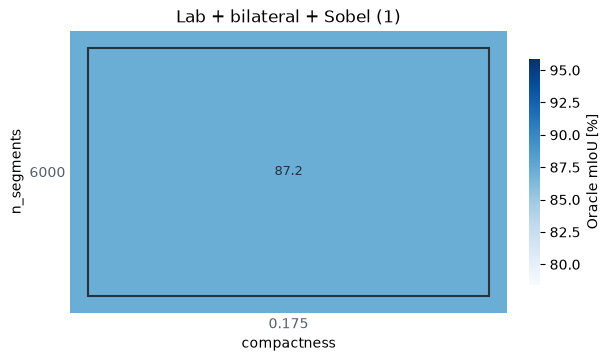

In [26]:
from matplotlib.patches import Rectangle

n_cols = min(2, len(variant_weights))
n_rows = (len(variant_weights) + n_cols - 1) // n_cols
fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(6 * n_cols, 3.5 * n_rows),
    squeeze=False, layout='constrained',
)
active_axes = list(axes.flat)[:len(variant_weights)]
for ax in list(axes.flat)[len(variant_weights):]:
    ax.set_visible(False)
min_miou = 100 * min(result['miou'] for result in results)
max_miou = 100 * BEST_CONFIG['miou']

for ax, (variant, weight) in zip(active_axes, variant_weights):
    scores = np.empty((len(N_SEGMENTS), len(COMPACTNESS)))
    for result in results:
        if (result['variant'], result['sobel_weight']) == (variant, weight):
            row = N_SEGMENTS.index(result['n_segments'])
            col = COMPACTNESS.index(result['compactness'])
            scores[row, col] = 100 * result['miou']

    heatmap = ax.imshow(
        scores, aspect='auto', origin='lower', cmap='Blues', vmin=min_miou, vmax=max_miou
    )
    best = best_by_case[(variant, weight)]
    best_row = N_SEGMENTS.index(best['n_segments'])
    best_col = COMPACTNESS.index(best['compactness'])

    for (row, col), score in np.ndenumerate(scores):
        red, green, blue, _ = heatmap.cmap(heatmap.norm(score))
        brightness = 0.2126 * red + 0.7152 * green + 0.0722 * blue
        text_color = '#27333D' if brightness > 0.58 else 'white'
        ax.text(col, row, f'{score:.1f}', ha='center', va='center', color=text_color, fontsize=9)
        if (row, col) == (best_row, best_col):
            ax.add_patch(Rectangle(
                (col - 0.46, row - 0.44), 0.92, 0.88,
                fill=False, edgecolor=text_color, linewidth=1.5,
            ))

    title = variant if weight is None else f'{variant} ({weight:g})'
    ax.set(
        title=title, xlabel='compactness', ylabel='n_segments',
        xticks=range(len(COMPACTNESS)), xticklabels=COMPACTNESS,
        yticks=range(len(N_SEGMENTS)), yticklabels=N_SEGMENTS,
    )
    ax.tick_params(length=0, colors='#53606B')
    for spine in ax.spines.values():
        spine.set_visible(False)

colorbar = fig.colorbar(heatmap, ax=active_axes, shrink=0.8, label='Oracle mIoU [%]')
colorbar.outline.set_visible(False)
plt.show()

## 5. Użycie zwycięskiej konfiguracji

`segments` zawiera identyfikator superpiksela dla każdego piksela obrazu. W kolejnych komórkach można wykorzystać tę mapę do wyznaczenia statystyk koloru, geometrii i innych cech regionów. Zmiana zdjęcia wymaga uruchomienia tylko tej komórki.

In [27]:
from matplotlib.colors import BoundaryNorm, ListedColormap

def make_mask_palette(n_classes):
    """Tworzy paletę kolorów klas fasady."""
    colors = ['#CFD4D9', '#365C7D', '#C99E5F', '#925D6B', '#659B8C', '#81729B', '#B87555', '#718053']
    mask_cmap = ListedColormap(colors)
    mask_norm = BoundaryNorm(np.arange(0.5, n_classes + 1), mask_cmap.N)
    return mask_cmap, mask_norm


def plot_superpixels(image, mask, segments, class_names):
    """Pokazuje obraz i maskę GT z granicami superpikseli."""
    class_ids = np.arange(1, len(class_names) + 1)
    mask_cmap, mask_norm = make_mask_palette(len(class_names))
    mask_rgb = mask_cmap(mask_norm(mask))[..., :3]
    boundary_color = (1, 0.82, 0.2)

    fig, axes = plt.subplots(2, 2, figsize=(10, 9), layout='constrained')
    axes[0, 0].imshow(image)
    axes[0, 0].set_title('Obraz RGB', loc='left')
    axes[0, 1].imshow(mark_boundaries(image, segments, color=boundary_color))
    axes[0, 1].set_title('Granice superpikseli na RGB', loc='left')

    mask_plot = axes[1, 0].imshow(mask, cmap=mask_cmap, norm=mask_norm, interpolation='nearest')
    axes[1, 0].set_title('Maska GT', loc='left')
    axes[1, 1].imshow(mark_boundaries(mask_rgb, segments, color=boundary_color))
    axes[1, 1].set_title('Granice superpikseli na masce GT', loc='left')

    for ax in axes.flat:
        ax.axis('off')

    colorbar = fig.colorbar(mask_plot, ax=axes[1], shrink=0.8, pad=0.03)
    colorbar.set_ticks(class_ids, labels=class_names)
    colorbar.outline.set_visible(False)
    plt.show()

Lab + bilateral + Sobel · 5341 superpikseli na zdjęciu val[12]


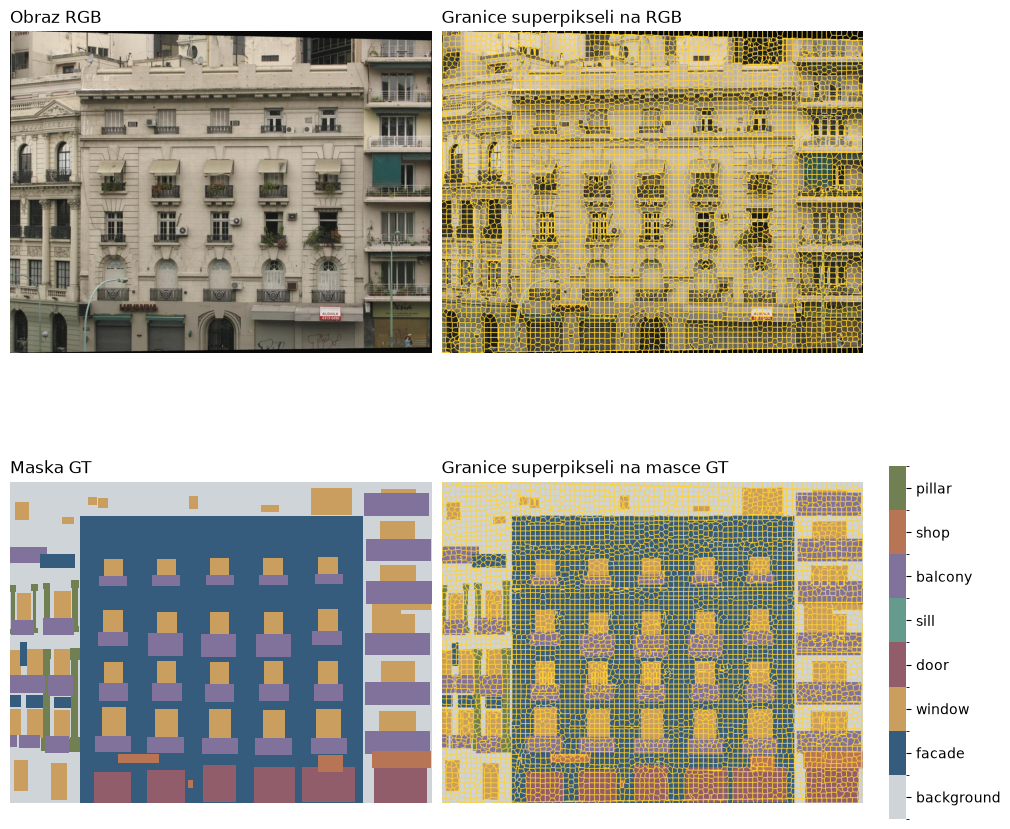

In [29]:
SPLIT_NAME = 'val'
IMAGE_INDEX = 12

image = data[SPLIT_NAME]['images'][IMAGE_INDEX]
mask = data[SPLIT_NAME]['masks'][IMAGE_INDEX]
segments = segment_image(image, BEST_CONFIG)

print(
    f"{BEST_CONFIG['variant']} · {np.unique(segments).size} superpikseli "
    f"na zdjęciu {SPLIT_NAME}[{IMAGE_INDEX}]"
)
plot_superpixels(image, mask, segments, class_names)

# Ekstrakcja cech

Jeden wiersz opisuje jeden superpiksel. Filtry liczymy na całym oryginalnym zdjęciu w Lab i agregujemy ich odpowiedzi w regionach SLIC. Bloki `lab_stats`, `geometry` i `sobel` dają razem 12 cech bazowych. W `FEATURE_BLOCKS` można włączać każdy blok osobno. Pełny zestaw zawiera 122 cechy.

`image_id` to indeks zdjęcia przed podziałem danych. Para `image_id` i `region_id` wskazuje region przy tej samej konfiguracji SLIC. `split` i `image_index` umożliwiają odczyt zdjęcia z `data`.

Blok `region_shape` opisuje wydłużenie i orientację regionu. Blok `neighbors` opisuje kontrast Lab i kierunkowego Sobela, siłę wspólnych granic oraz kontrast jasności względem sąsiadów drugiego stopnia.

In [30]:
import pandas as pd
from scipy.ndimage import gaussian_filter, gaussian_laplace, uniform_filter
from scipy.sparse import csr_matrix
from skimage.feature import local_binary_pattern
from skimage.filters import gabor_kernel, sobel_h, sobel_v

# Pierwsze trzy bloki dają 12 cech bazowych.
FEATURE_BLOCKS = (
    'lab_stats', 'geometry', 'sobel',
    'contrast', 'directional_sobel', 'local_std', 'log', 'gabor', 'lbp',
    'region_shape', 'neighbors',
)

CONTRAST_SCALES = (1, 2)
EDGE_SIGMAS = (1, 2, 4)
NEIGHBOR_SOBEL_SIGMA = 2
LOCAL_STD_WINDOWS = (7, 15, 31)
GABOR_WAVELENGTHS = (4, 8, 16)
GABOR_ANGLES = (0, 45, 90, 135)
LBP_RADII = (1, 3)

FEATURE_METADATA = {'split', 'image_index', 'image_id', 'region_id', 'label', 'purity'}

## Mapy filtrów i kontrasty między sąsiadami

In [31]:
GABOR_KERNELS = {}
if 'gabor' in FEATURE_BLOCKS:
    for wavelength in GABOR_WAVELENGTHS:
        for angle in GABOR_ANGLES:
            kernel = gabor_kernel(1 / wavelength, theta=np.deg2rad(angle), dtype=np.complex64)
            GABOR_KERNELS[wavelength, angle] = (
                np.ascontiguousarray(kernel.real), np.ascontiguousarray(kernel.imag)
            )


def filter_responses(lab, n_regions, blocks):
    """Udostępnia po jednej mapie odpowiedzi filtra."""
    lightness = lab[:, :, 0]
    typical_size = np.sqrt(lightness.size / n_regions)

    if 'contrast' in blocks:
        for channel, channel_name in zip(np.moveaxis(lab, -1, 0), ('l', 'a', 'b')):
            for scale in CONTRAST_SCALES:
                smooth = gaussian_filter(channel, sigma=scale * typical_size)
                yield f'contrast_{channel_name}_s{scale}', channel - smooth

    if 'directional_sobel' in blocks:
        for sigma in EDGE_SIGMAS:
            smooth = gaussian_filter(lightness, sigma=sigma)
            yield f'sobel_x_sigma{sigma}', np.abs(sobel_v(smooth))
            yield f'sobel_y_sigma{sigma}', np.abs(sobel_h(smooth))

    if 'local_std' in blocks:
        squared = lightness ** 2
        for window in LOCAL_STD_WINDOWS:
            mean = uniform_filter(lightness, size=window)
            variance = uniform_filter(squared, size=window) - mean ** 2
            yield f'local_std_w{window}', np.sqrt(np.maximum(variance, 0))

    if 'log' in blocks:
        for sigma in EDGE_SIGMAS:
            yield f'log_sigma{sigma}', gaussian_laplace(lightness, sigma=sigma)

    if 'gabor' in blocks:
        for (wavelength, angle), (real_kernel, imag_kernel) in GABOR_KERNELS.items():
            real = cv2.filter2D(lightness, -1, real_kernel, borderType=cv2.BORDER_REFLECT)
            imag = cv2.filter2D(lightness, -1, imag_kernel, borderType=cv2.BORDER_REFLECT)
            yield f'gabor_w{wavelength}_a{angle}', np.hypot(real, imag)


def region_shape_features(rows, cols, region_indices, pixel_counts, center_x, center_y):
    """Opisuje wydłużenie i orientację na podstawie współrzędnych pikseli regionu."""
    dx = cols - center_x[region_indices]
    dy = rows - center_y[region_indices]
    var_x = np.bincount(region_indices, weights=dx ** 2) / pixel_counts
    var_y = np.bincount(region_indices, weights=dy ** 2) / pixel_counts
    cov_xy = np.bincount(region_indices, weights=dx * dy) / pixel_counts

    eigen_gap = np.hypot(var_x - var_y, 2 * cov_xy)
    total_variance = var_x + var_y
    elongation = np.divide(
        eigen_gap, total_variance, out=np.zeros_like(eigen_gap), where=total_variance > 0
    )
    verticality = np.divide(
        var_y - var_x, eigen_gap, out=np.zeros_like(eigen_gap), where=eigen_gap > 0
    )
    return {'region_elongation': elongation, 'region_verticality': verticality}


def directional_edges(source, target, center_x, center_y):
    """Grupuje skierowane krawędzie według położenia środka sąsiada."""
    dx = center_x[target] - center_x[source]
    dy = center_y[target] - center_y[source]
    horizontal = np.abs(dx) >= np.abs(dy)
    return (
        ('left', horizontal & (dx < 0)),
        ('right', horizontal & (dx > 0)),
        ('up', ~horizontal & (dy < 0)),
        ('down', ~horizontal & (dy > 0)),
    )


def neighbor_features(regions, center_x, center_y, values, edge_map):
    """Liczy kontrasty i siłę granic na grafie regionów."""
    n_regions = len(center_x)
    contacts = []
    strengths = []
    for first, second, edge_first, edge_second in (
        (regions[:, :-1], regions[:, 1:], edge_map[:, :-1], edge_map[:, 1:]),
        (regions[:-1], regions[1:], edge_map[:-1], edge_map[1:]),
    ):
        boundary = first != second
        a, b = first[boundary], second[boundary]
        contacts.append(np.minimum(a, b) * n_regions + np.maximum(a, b))
        strengths.append((edge_first[boundary] + edge_second[boundary]) / 2)

    edge_ids, contact_index, contact_counts = np.unique(
        np.concatenate(contacts), return_inverse=True, return_counts=True
    )
    boundary_mean = np.bincount(contact_index, weights=np.concatenate(strengths)) / contact_counts
    a, b = np.divmod(edge_ids, n_regions)
    source = np.concatenate((a, b))
    target = np.concatenate((b, a))
    boundary_mean = np.tile(boundary_mean, 2)

    features = {}
    for direction, selected in directional_edges(source, target, center_x, center_y):
        src, dst = source[selected], target[selected]
        count = np.bincount(src, minlength=n_regions)
        for name, region_values in values.items():
            total = np.bincount(src, weights=region_values[dst], minlength=n_regions)
            average = np.divide(total, count, out=np.full(n_regions, np.nan), where=count > 0)
            features[f'{name}_{direction}'] = region_values - average

        total = np.bincount(src, weights=boundary_mean[selected], minlength=n_regions)
        features[f'neighbor_boundary_{direction}'] = np.divide(
            total, count, out=np.full(n_regions, np.nan), where=count > 0
        )

    adjacency = csr_matrix(
        (np.ones(source.size, dtype=np.int32), (source, target)), shape=(n_regions, n_regions)
    )
    second = adjacency @ adjacency
    second.setdiag(0)
    second = second - second.multiply(adjacency)
    second.eliminate_zeros()
    source, target = second.nonzero()

    lightness = values['contrast_neighbor']
    for direction, selected in directional_edges(source, target, center_x, center_y):
        src, dst = source[selected], target[selected]
        count = np.bincount(src, minlength=n_regions)
        total = np.bincount(src, weights=lightness[dst], minlength=n_regions)
        average = np.divide(total, count, out=np.full(n_regions, np.nan), where=count > 0)
        features[f'contrast_neighbor_2hop_l_{direction}'] = lightness - average

    return features

## Agregacja po superpikselach

In [32]:
def region_mean_std(values, region_indices, pixel_counts):
    """Liczy średnią i odchylenie standardowe w każdym regionie."""
    values = values.ravel()
    sums = np.bincount(region_indices, weights=values)
    squared_sums = np.bincount(region_indices, weights=np.square(values, dtype=np.float64))
    mean = sums / pixel_counts
    variance = squared_sums / pixel_counts - mean ** 2
    return mean, np.sqrt(np.maximum(variance, 0))


def extract_superpixel_features(image, segments, mask=None, blocks=('lab_stats', 'geometry', 'sobel')):
    """Zwraca tabelę cech superpikseli jednego zdjęcia."""
    if image.shape[:2] != segments.shape:
        raise ValueError('Obraz i mapa superpikseli muszą mieć te same wymiary.')
    if mask is not None and mask.shape != segments.shape:
        raise ValueError('Maska GT i mapa superpikseli muszą mieć te same wymiary.')

    height, width = segments.shape
    region_ids, region_indices = np.unique(segments.ravel(), return_inverse=True)
    pixel_counts = np.bincount(region_indices)
    lab = rgb2lab(image).astype(np.float32)

    features = {'region_id': region_ids}
    if any(block in blocks for block in ('geometry', 'region_shape', 'neighbors')):
        rows, cols = np.divmod(np.arange(segments.size), width)
        center_x = np.bincount(region_indices, weights=cols) / pixel_counts
        center_y = np.bincount(region_indices, weights=rows) / pixel_counts

    if 'lab_stats' in blocks:
        for channel, name in enumerate(('lab_l', 'lab_a', 'lab_b')):
            mean, std = region_mean_std(lab[:, :, channel], region_indices, pixel_counts)
            features[f'{name}_mean'] = mean
            features[f'{name}_std'] = std

    if 'geometry' in blocks:
        features['center_x'] = (center_x + 0.5) / width
        features['center_y'] = (center_y + 0.5) / height
        features['relative_area'] = pixel_counts / segments.size

    if 'sobel' in blocks or 'neighbors' in blocks:
        edges = sobel(lab[:, :, 0] / 100)

    if 'sobel' in blocks:
        features['sobel_mean'], features['sobel_std'] = region_mean_std(
            edges, region_indices, pixel_counts
        )

    if 'geometry' in blocks:
        left = np.full(len(region_ids), width)
        right = np.zeros(len(region_ids), dtype=int)
        top = np.full(len(region_ids), height)
        bottom = np.zeros(len(region_ids), dtype=int)
        np.minimum.at(left, region_indices, cols)
        np.maximum.at(right, region_indices, cols)
        np.minimum.at(top, region_indices, rows)
        np.maximum.at(bottom, region_indices, rows)
        features['bbox_aspect'] = (right - left + 1) / (bottom - top + 1)

    if 'region_shape' in blocks:
        features.update(region_shape_features(
            rows, cols, region_indices, pixel_counts, center_x, center_y
        ))

    for name, response in filter_responses(lab, pixel_counts.size, blocks):
        mean, std = region_mean_std(response, region_indices, pixel_counts)
        if name.startswith('log_'):
            features[f'{name}_mean'] = mean
            abs_sum = np.bincount(region_indices, weights=np.abs(response).ravel())
            features[f'{name}_abs_mean'] = abs_sum / pixel_counts
        else:
            features[f'{name}_mean'] = mean
            features[f'{name}_std'] = std

    if 'lbp' in blocks:
        lightness_uint8 = np.rint(lab[:, :, 0].clip(0, 100) * (255 / 100)).astype(np.uint8)
        for radius in LBP_RADII:
            pattern = local_binary_pattern(lightness_uint8, 8, radius, method='uniform')
            bins = pattern.ravel().astype(np.int64)
            counts = np.bincount(region_indices * 10 + bins, minlength=len(region_ids) * 10)
            histogram = counts.reshape(-1, 10) / pixel_counts[:, None]
            for bin_index in range(10):
                features[f'lbp_r{radius}_bin{bin_index}'] = histogram[:, bin_index]

    if 'neighbors' in blocks:
        neighbor_values = {}
        for channel, suffix in enumerate(('l', 'a', 'b')):
            mean = features.get(f'lab_{suffix}_mean')
            if mean is None:
                sums = np.bincount(region_indices, weights=lab[:, :, channel].ravel())
                mean = sums / pixel_counts
            name = 'contrast_neighbor' if suffix == 'l' else f'contrast_neighbor_{suffix}'
            neighbor_values[name] = mean

        sobel_x = features.get(f'sobel_x_sigma{NEIGHBOR_SOBEL_SIGMA}_mean')
        sobel_y = features.get(f'sobel_y_sigma{NEIGHBOR_SOBEL_SIGMA}_mean')
        if sobel_x is None:
            smooth = gaussian_filter(lab[:, :, 0], sigma=NEIGHBOR_SOBEL_SIGMA)
            sobel_x = np.bincount(region_indices, weights=np.abs(sobel_v(smooth)).ravel()) / pixel_counts
            sobel_y = np.bincount(region_indices, weights=np.abs(sobel_h(smooth)).ravel()) / pixel_counts
        neighbor_values['contrast_neighbor_sobel_x'] = sobel_x
        neighbor_values['contrast_neighbor_sobel_y'] = sobel_y

        features.update(neighbor_features(
            region_indices.reshape(segments.shape), center_x, center_y, neighbor_values, edges
        ))

    if mask is not None:
        gt = mask.ravel().astype(np.int64) - 1
        if gt.min() < 0 or gt.max() >= n_classes:
            raise ValueError('Maska GT zawiera etykietę spoza zakresu klas.')

        # Wiersze odpowiadają regionom, kolumny klasom.
        votes = np.bincount(
            region_indices * n_classes + gt, minlength=len(region_ids) * n_classes
        ).reshape(len(region_ids), n_classes)
        features['label'] = votes.argmax(axis=1) + 1
        features['purity'] = votes.max(axis=1) / pixel_counts

    for name, values in features.items():
        if values.dtype.kind == 'f':
            features[name] = values.astype(np.float32, copy=False)
    return pd.DataFrame(features)

In [33]:
sample_features = extract_superpixel_features(image, segments, mask, blocks=FEATURE_BLOCKS)
feature_columns = [column for column in sample_features if column not in FEATURE_METADATA]

print(f'{len(sample_features)} superpikseli · {len(feature_columns)} cech modelu')
sample_features.head()

5341 superpikseli · 122 cech modelu


,region_id,lab_l_mean,lab_l_std,lab_a_mean,lab_a_std,lab_b_mean,lab_b_std,center_x,center_y,relative_area,...,contrast_neighbor_b_down,contrast_neighbor_sobel_x_down,contrast_neighbor_sobel_y_down,neighbor_boundary_down,contrast_neighbor_2hop_l_left,contrast_neighbor_2hop_l_right,contrast_neighbor_2hop_l_up,contrast_neighbor_2hop_l_down,label,purity
0,0,18.484615,24.192997,-0.135931,1.303657,1.945780,1.717151,0.001595,0.078846,0.000507,...,-4.113252,6.741448,-1.597391,0.304864,NaN,-7.715209,-37.66613,-31.176012,1,1.0
1,1,61.811485,5.227892,0.339480,1.724552,9.835808,2.097845,0.007645,0.008482,0.000160,...,3.319474,-0.709949,-0.210940,0.191797,NaN,9.815938,NaN,17.354301,1,1.0
2,2,47.226315,9.074387,4.309038,1.451844,8.524253,1.180225,0.018674,0.007623,0.000195,...,-2.309147,0.369878,1.700037,0.070565,NaN,-16.683264,NaN,-0.472128,1,1.0
3,3,40.818531,12.194964,4.062115,1.467237,8.664327,1.115285,0.032077,0.005724,0.000155,...,-1.915588,1.083264,3.195571,0.113691,-19.637037,-35.084763,NaN,-24.380461,1,1.0
4,4,59.859798,9.605314,3.744076,1.099479,8.381946,0.980829,0.041126,0.007886,0.000116,...,-1.658110,3.069122,3.276874,0.020240,6.696815,-19.680391,NaN,-9.039762,1,1.0


## Przygotowanie zbiorów train i val

Zachowujemy mapy SLIC walidacji do odtworzenia masek pikselowych. Zbiór testowy przetwarzamy w końcowej sekcji.

In [35]:
def iter_image_features(split_name, config, blocks, with_labels=True):
    """Zwraca mapę SLIC i tabelę cech kolejnych zdjęć podziału."""
    split = data[split_name]
    images = tqdm(split['images'], desc=f'Ekstrakcja cech ({split_name})', unit='zdj.')
    for image_index, image in enumerate(images):
        segments = segment_image(image, config)
        mask = split['masks'][image_index] if with_labels else None
        table = extract_superpixel_features(image, segments, mask, blocks=blocks)
        table.insert(0, 'image_id', split['image_ids'][image_index])
        table.insert(0, 'image_index', image_index)
        table.insert(0, 'split', split_name)
        yield image_index, segments, table


def extract_split_features(split_name, config, blocks, keep_segments=False):
    """Łączy tabele cech i opcjonalnie zachowuje mapy SLIC."""
    tables = []
    segment_maps = []
    for _, segments, table in iter_image_features(split_name, config, blocks):
        tables.append(table)
        if keep_segments:
            segment_maps.append(segments.astype(np.int32, copy=False))

    return pd.concat(tables, ignore_index=True), segment_maps

In [36]:
train_features, _ = extract_split_features('train', BEST_CONFIG, FEATURE_BLOCKS)
val_features, val_segment_maps = extract_split_features(
    'val', BEST_CONFIG, FEATURE_BLOCKS, keep_segments=True
)

print(f'Train: {len(train_features):,} regionów · val: {len(val_features):,} regionów')
train_features[['split', 'image_index', 'image_id', 'region_id', 'label']].head()

Ekstrakcja cech (val): 100%|██████████| 91/91 [03:28<00:00,  2.29s/zdj.]

Train: 2,517,032 regionów · val: 546,722 regionów


,split,image_index,image_id,region_id,label
0,train,0,251,0,1
1,train,0,251,1,1
2,train,0,251,2,1
3,train,0,251,3,2
4,train,0,251,4,2


In [37]:
(
    pd.crosstab(
        train_features['label'],
        train_features['purity'].ge(0.75),
        normalize='index',
    )
    .reindex(columns=[False, True], fill_value=0)
    .rename(columns={False: 'purity < 75%', True: 'purity ≥ 75%'})
    .mul(100)
    .round(2)
)

purity,purity < 75%,purity ≥ 75%
label,,
1,5.70,94.30
2,7.73,92.27
3,11.72,88.28
4,8.01,91.99
5,20.87,79.13
6,10.95,89.05
7,8.03,91.97
8,23.21,76.79


# CatBoost

CatBoost monitoruje wieloklasowy log loss na regionach walidacyjnych i zachowuje drzewa do najlepszej iteracji. mIoU liczymy później na pikselach odtworzonych masek.

In [38]:
from catboost import CatBoostClassifier

CATBOOST_ITERATIONS = 10000
CATBOOST_EARLY_STOPPING_ROUNDS = 100
CATBOOST_DEPTH = 8
CATBOOST_LEARNING_RATE = 0.01
CATBOOST_GPU_DEVICES = '0'

baseline_model = CatBoostClassifier(
    loss_function='MultiClass',
    eval_metric='TotalF1:average=Macro;use_weights=false',
    iterations=CATBOOST_ITERATIONS,
    depth=CATBOOST_DEPTH,
    learning_rate=CATBOOST_LEARNING_RATE,
    random_seed=SEED,
    task_type='GPU',
    auto_class_weights='SqrtBalanced',
    devices=CATBOOST_GPU_DEVICES,
    allow_writing_files=False,
    verbose=100,
)
baseline_model.fit(
    train_features[feature_columns], train_features['label'],
    sample_weight=train_features['purity'],
    eval_set=(val_features[feature_columns], val_features['label']),
    early_stopping_rounds=CATBOOST_EARLY_STOPPING_ROUNDS,
    use_best_model=True,
)
print(f'Zachowane drzewa: {baseline_model.tree_count_}')

0:	learn: 0.2786467	test: 0.2812965	best: 0.2812965 (0)	total: 326ms	remaining: 54m 20s
100:	learn: 0.3194001	test: 0.3194423	best: 0.3194423 (100)	total: 27.3s	remaining: 44m 31s
200:	learn: 0.3530117	test: 0.3467337	best: 0.3467337 (200)	total: 52.5s	remaining: 42m 41s
300:	learn: 0.3810364	test: 0.3711788	best: 0.3711788 (300)	total: 1m 18s	remaining: 42m 3s
400:	learn: 0.3998566	test: 0.3886037	best: 0.3886037 (400)	total: 1m 44s	remaining: 41m 49s
500:	learn: 0.4155218	test: 0.4015132	best: 0.4015132 (500)	total: 2m 12s	remaining: 41m 46s
600:	learn: 0.4280194	test: 0.4110175	best: 0.4110175 (600)	total: 2m 39s	remaining: 41m 30s
700:	learn: 0.4379371	test: 0.4178714	best: 0.4178714 (700)	total: 3m 5s	remaining: 41m 4s
800:	learn: 0.4458871	test: 0.4228144	best: 0.4228238 (799)	total: 3m 32s	remaining: 40m 38s
900:	learn: 0.4528186	test: 0.4267734	best: 0.4267734 (900)	total: 3m 58s	remaining: 40m 8s
1000:	learn: 0.4594297	test: 0.4300316	best: 0.4300316 (1000)	total: 4m 24s	remai

,Ważność
center_y,14.40
lab_l_mean,10.55
lab_b_mean,8.51
lab_a_mean,5.58
center_x,4.79
contrast_l_s2_mean,3.25
local_std_w31_mean,2.61
contrast_b_s2_mean,2.41
gabor_w16_a90_mean,1.67
relative_area,1.66


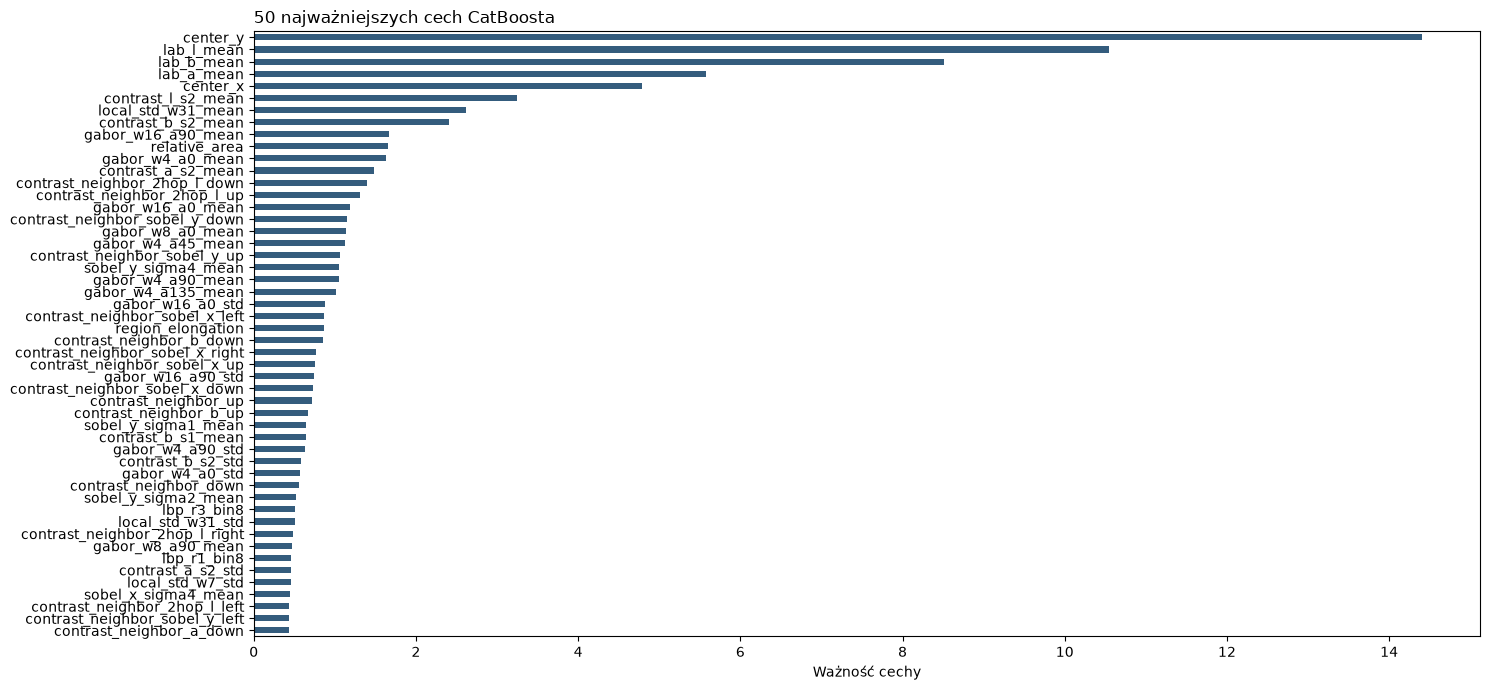

In [54]:
importance = pd.Series(
    baseline_model.get_feature_importance(type='PredictionValuesChange'),
    index=baseline_model.feature_names_,
    name='Ważność',
).sort_values(ascending=False)

display(importance.head(50).round(2).to_frame())

ax = importance.head(50).sort_values().plot.barh(
    figsize=(15, 7), color='#345C7D'
)
ax.set_xlabel('Ważność cechy')
ax.set_title('50 najważniejszych cech CatBoosta', loc='left')
plt.tight_layout()
plt.show()

# Ocena pikselowa

Każdy piksel otrzymuje klasę przewidzianą dla swojego superpiksela. IoU liczymy po zsumowaniu macierzy pomyłek dla wszystkich zdjęć.

In [39]:
def evaluate_segmentation(split_name, model, image_features, preview_indices=()):
    """Odtwarza maski i zlicza pomyłki na pikselach."""
    masks = data[split_name]['masks']
    confusion = np.zeros((n_classes, n_classes), dtype=np.int64)
    previews = {}

    for index, segments, features in image_features:
        labels = model.predict(features[model.feature_names_]).ravel()
        region_ids = features['region_id'].to_numpy()
        class_by_region = np.empty(int(region_ids.max()) + 1, dtype=np.uint8)
        class_by_region[region_ids] = labels
        prediction = class_by_region[segments]

        gt = masks[index].ravel().astype(np.int64) - 1
        pred = prediction.ravel().astype(np.int64) - 1
        counts = np.bincount(gt * n_classes + pred, minlength=n_classes ** 2)
        confusion += counts.reshape(n_classes, n_classes)

        if index in preview_indices:
            previews[index] = prediction

    return confusion, previews


def segmentation_scores(split_name, confusion):
    """Wyświetla mIoU i pixel accuracy oraz zwraca IoU klas."""
    iou = class_iou(confusion)
    accuracy = confusion.trace() / confusion.sum()
    print(f'{split_name} · mIoU: {np.nanmean(iou):.2%} · pixel accuracy: {accuracy:.2%}')
    return pd.DataFrame({'IoU [%]': (100 * iou).round(2)}, index=pd.Index(class_names, name='Klasa'))

In [40]:
def plot_confusion_matrix(confusion, split_name):
    """Pokazuje procent pikseli w każdej klasie GT."""
    totals = confusion.sum(axis=1, keepdims=True)
    percentages = np.divide(
        100.0 * confusion, totals, out=np.zeros_like(confusion, dtype=float), where=totals > 0
    )

    fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
    heatmap = ax.imshow(percentages, cmap='Blues', vmin=0, vmax=100)
    ticks = np.arange(len(class_names))
    ax.set_xticks(ticks, class_names, rotation=35, ha='right')
    ax.set_yticks(ticks, class_names)
    ax.set_xlabel('Klasa przewidziana')
    ax.set_ylabel('Klasa GT')
    ax.set_title(f'Macierz pomyłek · {split_name}', loc='left')
    fig.colorbar(heatmap, ax=ax, label='Piksele danej klasy GT [%]', shrink=0.8)

    for (row, col), value in np.ndenumerate(percentages):
        label = f'{value:.1f}' if totals[row, 0] else '–'
        color = 'white' if value >= 60 else '#243549'
        ax.text(col, row, label, ha='center', va='center', color=color, fontsize=9)

    plt.show()

## Macierz pomyłek na train

Sumujemy pomyłki na pikselach ze wszystkich zdjęć. Wiersz pokazuje, jak rozłożyły się predykcje dla jednej klasy GT. Dla `train` odtwarzamy mapy SLIC z konfiguracji użytej przy ekstrakcji i wczytujemy cechy z gotowej tabeli.

Ocena pikselowa train: 100%|██████████| 424/424 [06:00<00:00,  1.17zdj./s]


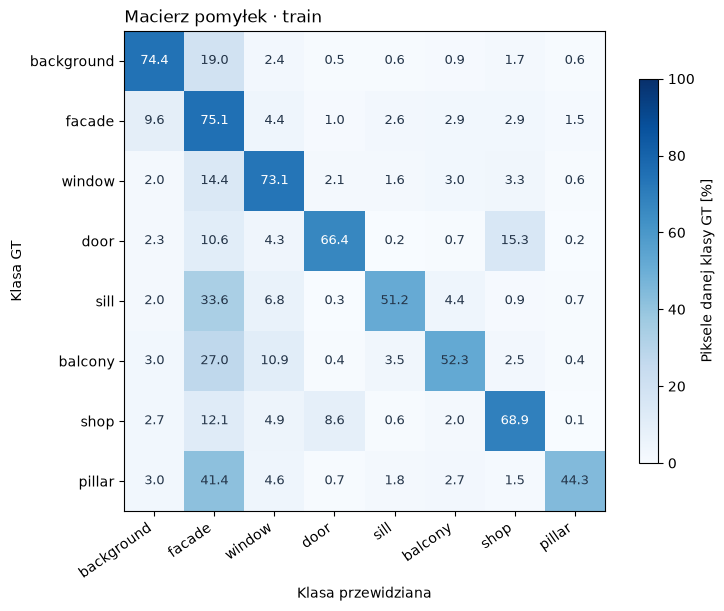

In [41]:
train_images = data['train']['images']
train_image_features = (
    (index, segment_image(train_images[index], BEST_CONFIG), table)
    for index, table in train_features.groupby('image_index', sort=False)
)
train_confusion, _ = evaluate_segmentation(
    'train', baseline_model,
    tqdm(train_image_features, total=len(train_images), desc='Ocena pikselowa train', unit='zdj.'),
)
plot_confusion_matrix(train_confusion, 'train')

## Walidacja pikselowa

In [42]:
VAL_PREVIEW_INDICES = list(range(40,51))

val_image_features = (
    (index, val_segment_maps[index], table)
    for index, table in val_features.groupby('image_index', sort=False)
)
val_confusion, val_predictions = evaluate_segmentation(
    'val', baseline_model,
    tqdm(val_image_features, total=len(val_segment_maps), desc='Walidacja pikselowa', unit='zdj.'),
    VAL_PREVIEW_INDICES,
)
segmentation_scores('val', val_confusion)

Walidacja pikselowa: 100%|██████████| 91/91 [00:06<00:00, 13.58zdj./s]

val · mIoU: 33.04% · pixel accuracy: 66.69%


,IoU [%]
Klasa,
background,49.55
facade,58.47
window,55.02
door,19.91
sill,18.38
balcony,23.09
shop,28.57
pillar,11.32


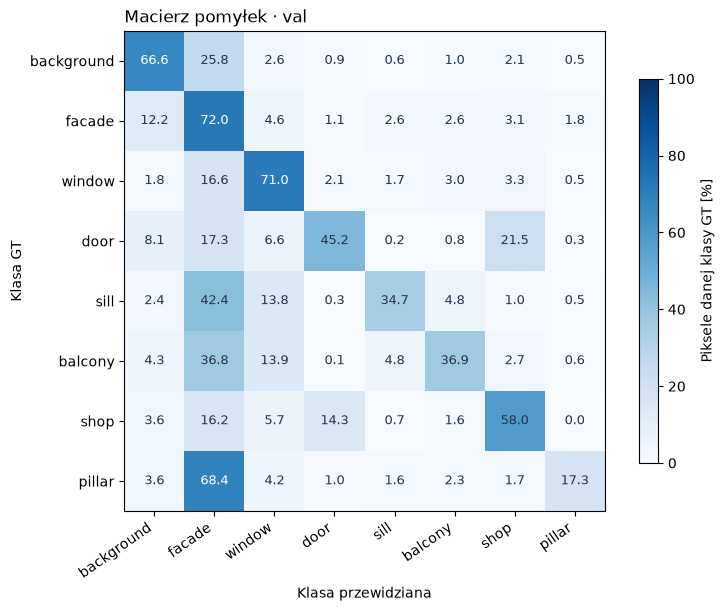

In [43]:
plot_confusion_matrix(val_confusion, 'val')

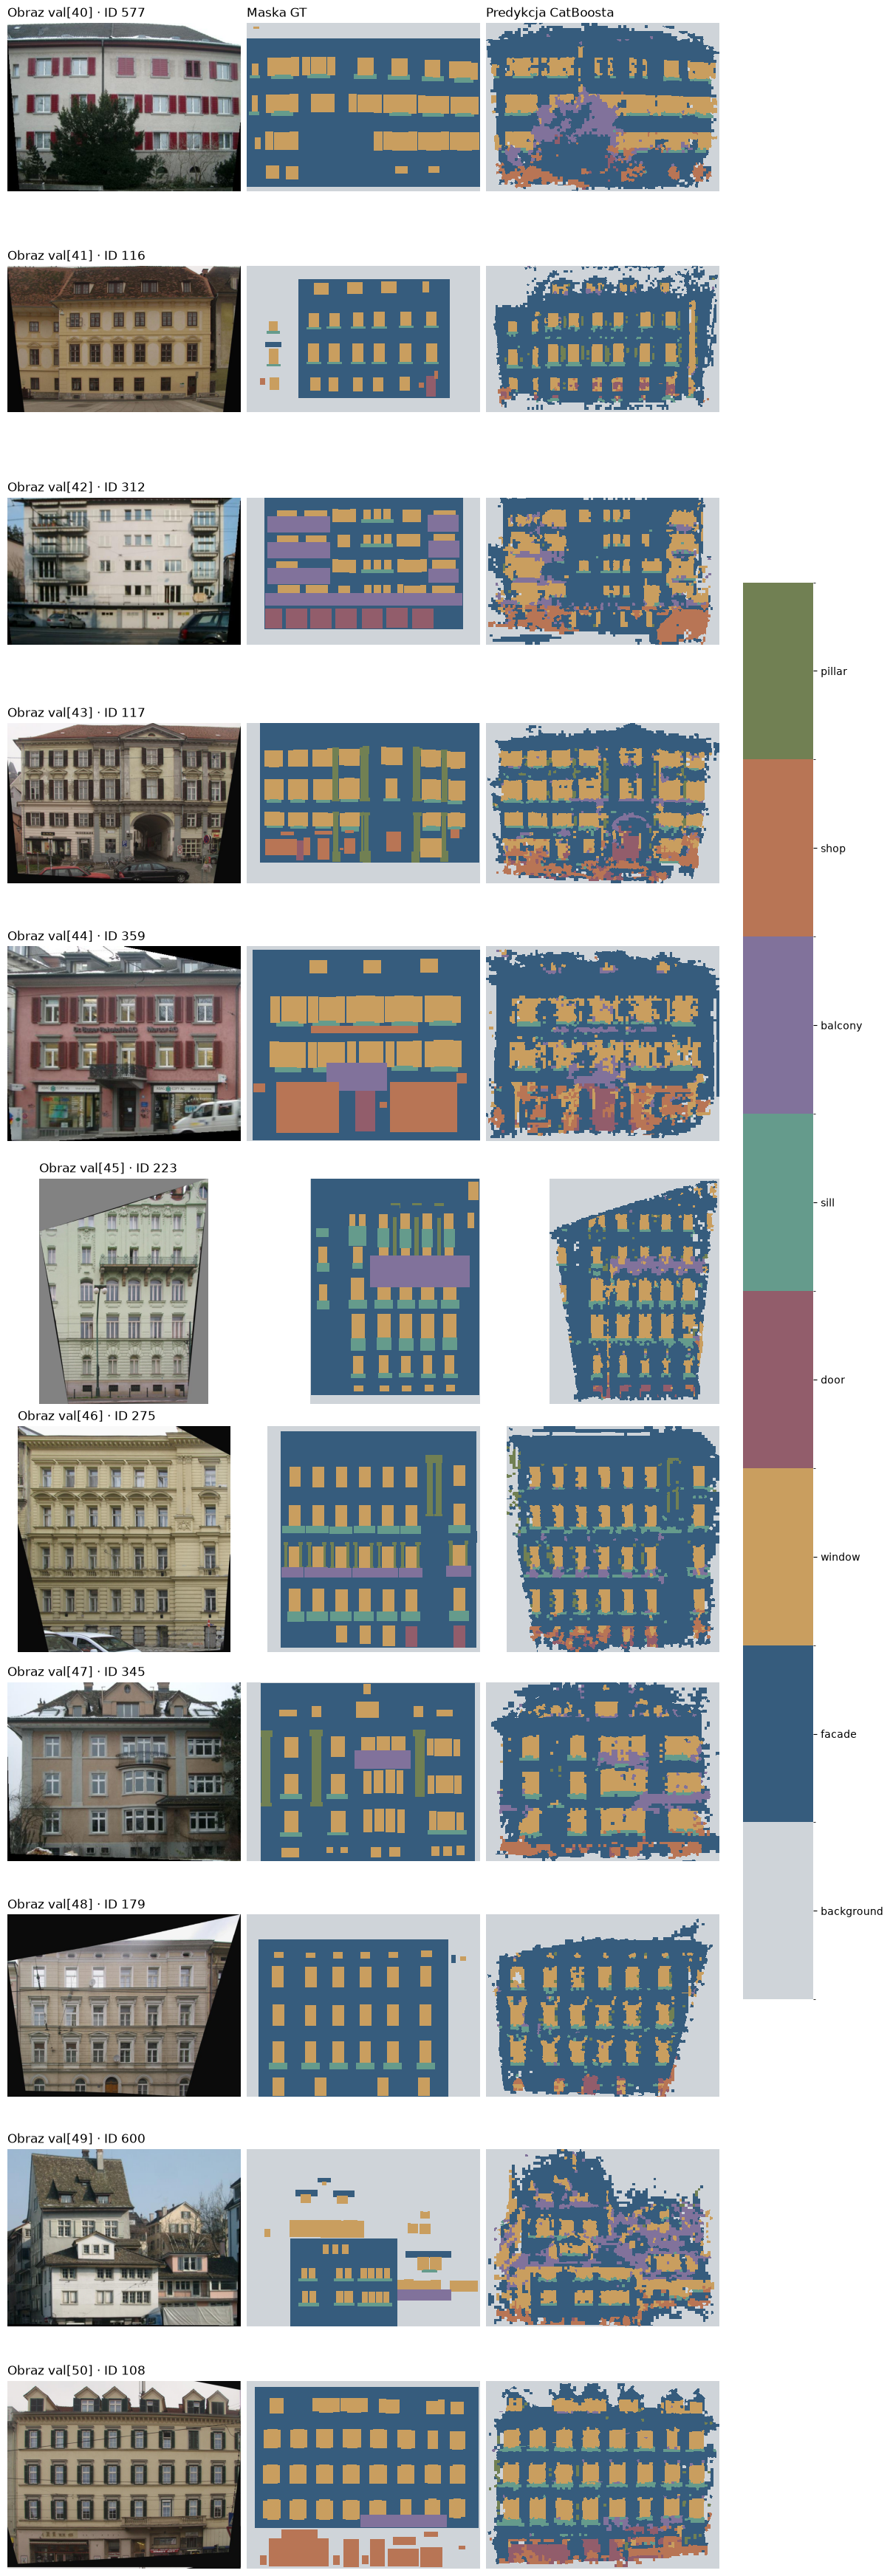

In [44]:
def plot_segmentation_predictions(split_name, predictions, class_names):
    """Pokazuje obraz RGB, maskę GT i predykcję dla wybranych zdjęć."""
    split = data[split_name]
    cmap, norm = make_mask_palette(len(class_names))
    fig, axes = plt.subplots(
        len(predictions), 3, figsize=(12, 3.2 * len(predictions)),
        squeeze=False, layout='constrained',
    )

    for (index, prediction), (image_ax, gt_ax, pred_ax) in zip(predictions.items(), axes):
        image_ax.imshow(split['images'][index])
        image_ax.set_title(f"Obraz {split_name}[{index}] · ID {split['image_ids'][index]}", loc='left')
        gt_ax.imshow(split['masks'][index], cmap=cmap, norm=norm, interpolation='nearest')
        prediction_plot = pred_ax.imshow(prediction, cmap=cmap, norm=norm, interpolation='nearest')

        for ax in (image_ax, gt_ax, pred_ax):
            ax.axis('off')

    axes[0, 1].set_title('Maska GT', loc='left')
    axes[0, 2].set_title('Predykcja CatBoosta', loc='left')
    colorbar = fig.colorbar(prediction_plot, ax=axes[:, 1:], shrink=0.8)
    colorbar.set_ticks(np.arange(1, len(class_names) + 1), labels=class_names)
    colorbar.outline.set_visible(False)
    plt.show()



plot_segmentation_predictions('val', val_predictions, class_names)

# Test końcowy

Po wyborze konfiguracji na walidacji ustaw `RUN_FINAL_TEST = True` i uruchom poniższą komórkę. Wynik pochodzi z modelu zachowanego przez early stopping.

Ekstrakcja cech (test): 100%|██████████| 91/91 [03:40<00:00,  2.43s/zdj.]

test · mIoU: 33.07% · pixel accuracy: 66.88%


,IoU [%]
Klasa,
background,53.97
facade,58.44
window,54.22
door,20.87
sill,19.44
balcony,20.75
shop,27.34
pillar,9.49


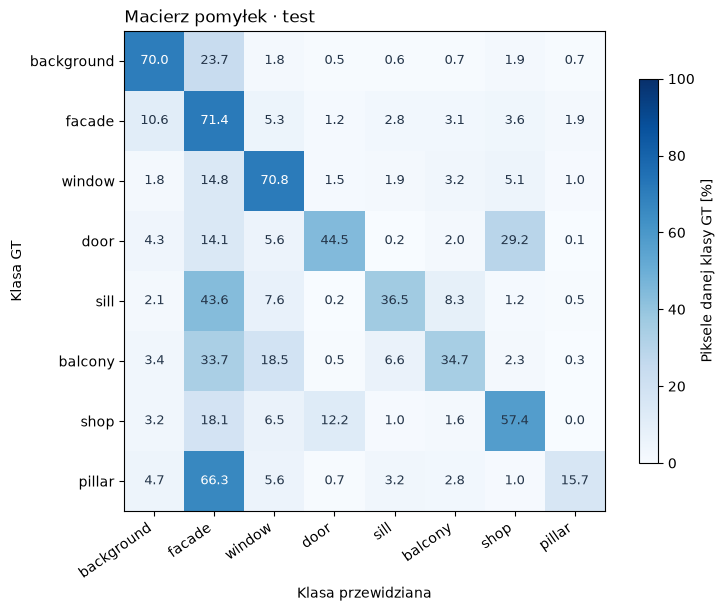

In [46]:
RUN_FINAL_TEST = True

if RUN_FINAL_TEST:
    test_confusion, _ = evaluate_segmentation(
        'test', baseline_model,
        iter_image_features('test', BEST_CONFIG, FEATURE_BLOCKS, with_labels=False),
    )
    display(segmentation_scores('test', test_confusion))
    plot_confusion_matrix(test_confusion, 'test')

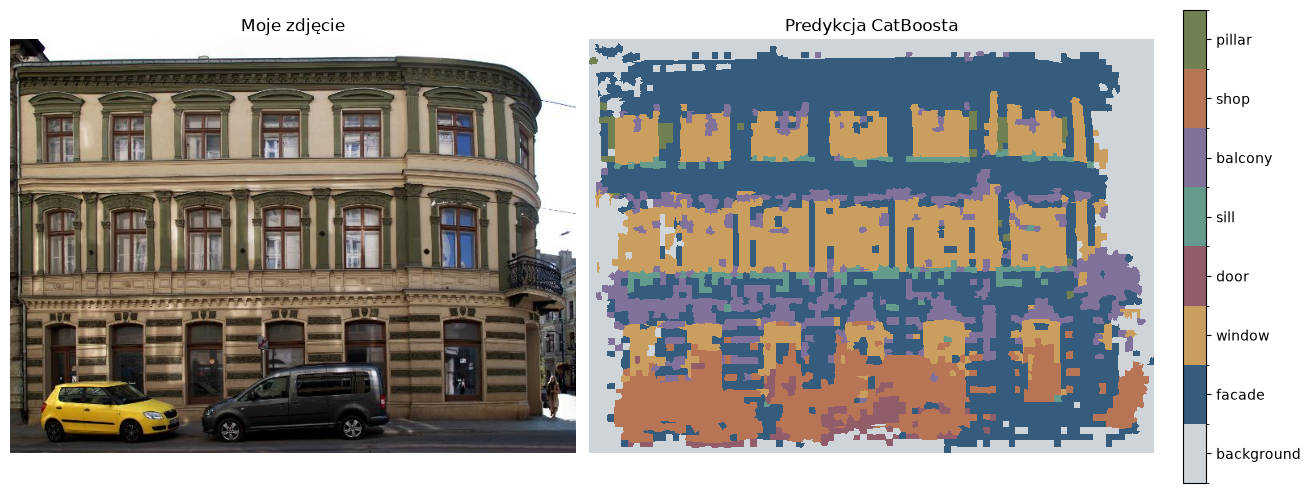

In [52]:
from PIL import Image, ImageOps

PHOTO_PATH = 'examples/pietryna_zabytek2.jpg'

with Image.open(PHOTO_PATH) as photo:
    custom_image = np.array(ImageOps.exif_transpose(photo).convert('RGB'))

custom_segments = segment_image(custom_image, BEST_CONFIG)
custom_features = extract_superpixel_features(
    custom_image, custom_segments, blocks=FEATURE_BLOCKS
)

# Jedna przewidziana klasa dla każdego superpiksela.
region_labels = baseline_model.predict(
    custom_features[baseline_model.feature_names_]
).ravel()

class_by_region = np.zeros(custom_segments.max() + 1, dtype=np.uint8)
class_by_region[custom_features['region_id'].to_numpy()] = region_labels
prediction = class_by_region[custom_segments]

cmap, norm = make_mask_palette(n_classes)
fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout='constrained')

axes[0].imshow(custom_image)
axes[0].set_title('Moje zdjęcie')
pred_plot = axes[1].imshow(prediction, cmap=cmap, norm=norm, interpolation='nearest')
axes[1].set_title('Predykcja CatBoosta')

for ax in axes:
    ax.axis('off')

colorbar = fig.colorbar(pred_plot, ax=axes[1], shrink=0.8)
colorbar.set_ticks(np.arange(1, n_classes + 1), labels=class_names)
plt.show()